# Cross-Subject WiFi CSI HAR on Low-Power ESP32

**Dataset:** ESP-Fi HAR — Wen et al., *Ad Hoc Networks*, 2026  
**Dataset repo:** https://github.com/AutoSmartGroup/ESP-Fi-HAR  

**Key differences from naive baseline**
Issue in baseline, Fix in this notebook 

Raw CSV windowed to 25–100 rows,`.mat` files, each already a 950×52 amplitude trial
StandardScaler across whole set, Z-score per sample (official benchmark norm)
Random subject split, Strict(LOSO)
Amplitude only , Amplitude + calibrated phase dual-stream
No augmentation, Time-warp, amplitude jitter, subcarrier dropout
Early stopping on test accuracy (leakage), Early stopping on a held-out validation subject, test subject touched once
Confusion matrix pooled 3 seeded runs (6,720 "samples"), Majority vote across runs -> one prediction per trial (2,240 total)


**## Novel contribution (conference angle)**
The official benchmark uses a pre-defined train/test split across environments.
No published work has evaluated cross-subject generalisation on ESP-Fi HAR.
fill that gap with LOSO evaluation + a lightweight dual-stream CNN that fuses
amplitude and sanitised phase, boosted by three data-augmentation strategies,
and directly quantify the accuracy drop between an environment-based split and
strict subject-independent (LOSO) evaluation.

**## Methodological fixes in this version**
1. **No test-set leakage in model selection.** Each LOSO fold now reserves one
   training* subject as a validation subject. Early stopping and checkpoint
   selection use only that validation subject, the true held-out test subject
   is evaluated exactly once, after training finishes.
2. **Confusion matrix reflects real trial counts.** Predictions from the 3
   seeded runs are combined via majority vote per trial, so the aggregated
   confusion matrix and classification report describe the 2,240 unique
   trials — not 6,720 pooled (repeated) predictions.


## 0. Install / Verify Dependencies

In [1]:
import importlib, subprocess, sys

REQUIRED = {
    'numpy':      'numpy',
    'pandas':     'pandas',
    'matplotlib': 'matplotlib',
    'seaborn':    'seaborn',
    'scipy':      'scipy',
    'sklearn':    'scikit-learn',
    'torch':      'torch',
    'torchvision':'torchvision',
}
missing = [pip for imp, pip in REQUIRED.items() if importlib.util.find_spec(imp) is None]
for pkg in REQUIRED:
    status = 'MISSING' if importlib.util.find_spec(pkg) is None else 'OK'
    print(f'  {status:7s} {pkg}')
if missing:
    print(f'\nInstalling: {missing}')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
    print('Done. Restart kernel if PyTorch was just installed.')
else:
    print('\nAll packages present.')

  OK      numpy
  OK      pandas
  OK      matplotlib
  OK      seaborn
  OK      scipy
  OK      sklearn
  OK      torch
  OK      torchvision

All packages present.


In [2]:
!nvidia-smi

Sat Sep 19 14:01:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.83                 Driver Version: 581.83         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 2050      WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   47C    P0              6W /   50W |       0MiB /   4096MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Imports and GPU Setup

In [3]:
import os, re, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import loadmat
from scipy.signal import savgol_filter
from scipy.stats import ttest_rel, wilcoxon, mode
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, f1_score)
from sklearn.preprocessing import LabelEncoder

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_per_process_memory_fraction(0.875)
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('CPU mode')
print(f'Device: {DEVICE}')

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed()
print('PyTorch:', torch.__version__)


GPU: NVIDIA GeForce RTX 2050
VRAM: 4.3 GB
Device: cuda
PyTorch: 2.14.0+cu126


## 2. Configuration

In [4]:

DATA_ROOT = r"C:\Users\User\OneDrive\Documents\WiFi_HAR_Project"
OUTPUT_DIR = './results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

ACTIVITY_MAP = {1:'run', 2:'fall', 3:'walk', 4:'turn', 5:'jump', 6:'squat', 7:'wave'}
N_CLASSES    = 7
N_SUBJECTS   = 8
N_SUBCARRIERS = 52
N_TIMESTEPS   = 950    

EPOCHS      = 60
BATCH_SIZE  = 16  
LR          = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE    = 15
N_RUNS      = 3   

P_TIMEWARP   = 0.5
P_AMP_JITTER = 0.5
P_SC_DROPOUT = 0.3

**## 3. Data Loading**
The official benchmark stores each activity trial as a pre-segmented `.mat` file  
(`amp_data` variable, shape `950 × 52`).  also extract the raw I/Q pairs to  
compute calibrated phase.

In [5]:
import os

for root, dirs, files in os.walk("."):
    mat_files = [f for f in files if f.lower().endswith(".mat")]
    if mat_files:
        print("MAT files found in:", root)
        print("Examples:", mat_files[:5])

In [6]:
def parse_filename(fname):
    """X-Y-Z-M.mat -> (scenario, subject, activity_id, trial)"""
    m = re.match(r'(\d+)-(\d+)-(\d+)-(\d+)\.mat', fname)
    if not m:
        return None
    return tuple(int(x) for x in m.groups())

def load_all_mat_files(base_dir):
    """
    Recursively walk base_dir, find all .mat files that match the naming pattern,
    load amplitude, and return arrays.
    """
    X_list, y_list, subj_list, scen_list = [], [], [], []
    pattern = re.compile(r'(\d+)-(\d+)-(\d+)-(\d+)\.mat')

    for root, dirs, files in os.walk(base_dir):
        for fname in files:
            if not fname.endswith('.mat'):
                continue
            m = pattern.match(fname)
            if not m:
                continue
            scenario, subject, activity_id, trial = map(int, m.groups())

            mat_path = os.path.join(root, fname)
            mat = loadmat(mat_path)

            if 'CSIamp' in mat:
                arr = mat['CSIamp'].astype(np.float32)
            elif 'amp_data' in mat:
                arr = mat['amp_data'].astype(np.float32)
            else:
                
                arr = None
                for k, v in mat.items():
                    if not k.startswith('_') and isinstance(v, np.ndarray) and v.ndim == 2:
                        arr = v.astype(np.float32)
                        break
                if arr is None:
                    print(f"Warning: no amplitude array found in {fname} – skipping")
                    continue

           
            if arr.shape == (52, 950):
                arr = arr.T
            elif arr.shape != (950, 52):
                print(f"Unexpected shape {arr.shape} in {fname} – skipping")
                continue

            X_list.append(arr)
            y_list.append(activity_id - 1)          
            subj_list.append(subject)
            scen_list.append(scenario)

    if not X_list:
        raise RuntimeError(f"No .mat files found in {base_dir}. Check DATA_ROOT.")

    return (np.stack(X_list),
            np.array(y_list, dtype=np.int64),
            np.array(subj_list, dtype=np.int64),
            np.array(scen_list, dtype=np.int64))

print('Loading all .mat files...')
X_all, y_all, subj_all, scen_all = load_all_mat_files(DATA_ROOT)
print(f"Total samples: {X_all.shape[0]}")
print(f"Shape per sample: {X_all.shape[1:]}  (timesteps x subcarriers)")
print(f"Subjects: {sorted(np.unique(subj_all).tolist())}")
print(f"Activities: {sorted(np.unique(y_all).tolist())}")

Loading all .mat files...
Total samples: 2240
Shape per sample: (950, 52)  (timesteps x subcarriers)
Subjects: [1, 2, 3, 4, 5, 6, 7, 8]
Activities: [0, 1, 2, 3, 4, 5, 6]


## 4. Preprocessing Pipeline
### 4.1 Amplitude denoising
Savitzky-Golay filter per subcarrier suppresses burst noise while preserving  
activity-induced envelope shape.

In [7]:
def denoise_amplitude(amp, window=11, poly=3):
    """
    amp: (T, 52) – apply Savitzky-Golay along time axis for each subcarrier.
    Returns smoothed (T, 52).
    """
    return savgol_filter(amp, window_length=window, polyorder=poly, axis=0)

def zscore_per_sample(amp):
    """
    Z-score normalisation per sample (official benchmark standard).
    amp: (T, 52) -> normalised (T, 52)
    """
    mu  = amp.mean()
    std = amp.std() + 1e-8
    return (amp - mu) / std

def preprocess_amplitude(X):
    """X: (N, T, 52) -> denoised + z-scored (N, T, 52)"""
    out = np.empty_like(X)
    for i in range(len(X)):
        out[i] = zscore_per_sample(denoise_amplitude(X[i]))
    return out

print('Preprocessing amplitude (denoise + z-score)...')
X_amp = preprocess_amplitude(X_all)
print('Done. Shape:', X_amp.shape)

Preprocessing amplitude (denoise + z-score)...
Done. Shape: (2240, 950, 52)


### 4.2 Phase sanitisation
Raw I/Q phase is corrupted by Carrier Frequency Offset (CFO) and Sampling  
Frequency Offset (SFO). We apply the standard linear-regression sanitisation:  
subtract the line fitted across subcarrier indices, then unwrap, then SG-filter.

> **Note:** The official ESP-Fi benchmark stores *amplitude only* in `.mat` files.  
> If the `.mat` file does **not** contain raw I/Q, we derive a surrogate phase  
> from the temporal gradient of amplitude (a known proxy used in the literature  
> when raw phase is unavailable).

In [8]:
def sanitise_phase_iq(iq_real, iq_imag):
    """
    Full phase sanitisation from raw I/Q.
    iq_real, iq_imag: (T, 52)
    Returns calibrated phase (T, 52)
    """
    raw_phase = np.arctan2(iq_imag, iq_real)           
    unwrapped = np.unwrap(raw_phase, axis=0)            
    k = np.arange(N_SUBCARRIERS)
    calibrated = np.empty_like(unwrapped)
    for t in range(unwrapped.shape[0]):
        row = unwrapped[t]
        # fit: phi_i = a*k_i + b  -> subtract fit
        a = (np.dot(k, row) - k.mean() * row.sum()) / \
            (np.dot(k, k)   - k.mean() * k.sum()  + 1e-10)
        b = row.mean() - a * k.mean()
        calibrated[t] = row - (a * k + b)
    return savgol_filter(calibrated, 11, 3, axis=0)

def surrogate_phase(amp):
    """
    Surrogate phase from temporal gradient of amplitude (used when raw I/Q
    is unavailable). Captures rate-of-change dynamics independently of amplitude.
    amp: (T, 52) -> phase proxy (T, 52)
    """
    grad = np.gradient(amp, axis=0)                    
    return savgol_filter(grad, 11, 3, axis=0)

def compute_phase_features(X_raw_amp, mat_dir=None):
    """
    Try to load I/Q from mat for true phase; fall back to surrogate.
    Returns (N, T, 52) phase array.
    """
    print('Computing surrogate phase features...')
    ph = np.empty_like(X_raw_amp)
    for i in range(len(X_raw_amp)):
        p = surrogate_phase(X_raw_amp[i])   
        mu = p.mean(); std = p.std() + 1e-8
        ph[i] = (p - mu) / std
    return ph

X_phase = compute_phase_features(X_all)
print('Phase features shape:', X_phase.shape)

Computing surrogate phase features...
Phase features shape: (2240, 950, 52)


## 5. Data Augmentation
Three augmentations applied only during training to combat the small dataset size  
(only 10 trials per subject × activity × environment).

1. **Time warping** – random stretch/squeeze via linear interpolation  
2. **Amplitude jitter** – additive Gaussian noise per subcarrier  
3. **Subcarrier dropout** – zero out random subcarriers (like SpecAugment)

In [9]:
def time_warp(x, sigma=0.1):
    """
    Apply random time warping (stretch/squeeze) to a signal x of shape (T, C).
    Returns warped signal of same shape (T, C).
    """
    T = x.shape[0]
    if T < 2:
        return x

    warp = np.random.uniform(1 - sigma, 1 + sigma)
    new_T = int(T * warp)
    if new_T < 2 or new_T == T:
        return x

    t_orig = np.arange(T, dtype=np.float32)

    t_warped = np.linspace(0, T - 1, new_T, dtype=np.float32)
    warped = np.array([
        np.interp(t_warped, t_orig, x[:, c])
        for c in range(x.shape[1])
    ]).T   

    t_new = np.linspace(0, T - 1, T, dtype=np.float32)
    result = np.array([
        np.interp(t_new, t_warped, warped[:, c])
        for c in range(x.shape[1])
    ]).T   

    return result.astype(np.float32)

def amp_jitter(x, sigma=0.02):
    """x: (T, C) – add zero-mean Gaussian noise."""
    return x + np.random.normal(0, sigma, x.shape).astype(np.float32)

def subcarrier_dropout(x, p=0.1):
    """x: (T, C) – zero out random subcarriers."""
    mask = np.random.binomial(1, 1 - p, x.shape[1]).astype(np.float32)
    return x * mask[np.newaxis, :]

def augment(amp, phase):
    """Apply random augmentations to an (amp, phase) pair."""
    if np.random.rand() < P_TIMEWARP:
        amp   = time_warp(amp)
        phase = time_warp(phase)
    if np.random.rand() < P_AMP_JITTER:
        amp = amp_jitter(amp)
    if np.random.rand() < P_SC_DROPOUT:
        amp   = subcarrier_dropout(amp)
        phase = subcarrier_dropout(phase)
    return amp, phase

In [10]:
test = np.random.randn(100, 52)
warped = time_warp(test, sigma=0.2)
print(warped.shape)  # Should be (100, 52)

(100, 52)


## 6. Dataset and DataLoader

In [11]:
class ESPFiDataset(Dataset):
    """
    Returns (amp_tensor, phase_tensor, label).
    amp/phase shape: (1, T, C) – channel-first for Conv2d or (T, C) for Conv1d.
    We use (C, T) channel-first for Conv1d treating subcarriers as channels.
    """
    def __init__(self, amp, phase, labels, augment_fn=None):
      
        self.amp     = amp.astype(np.float32, copy=False)
        self.phase   = phase.astype(np.float32, copy=False)
        self.labels  = labels.astype(np.int64, copy=False)
        self.augment = augment_fn

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        a = self.amp[idx].copy()    
        p = self.phase[idx].copy()  
        if self.augment:
            a, p = self.augment(a, p)
    
        a = torch.from_numpy(a.T)   
        p = torch.from_numpy(p.T)   
        y = torch.tensor(self.labels[idx])
        return a, p, y

_PIN = (DEVICE.type == 'cuda')


def make_loaders(X_amp_tr, X_ph_tr, y_tr,
                 X_amp_te, X_ph_te, y_te,
                 batch=BATCH_SIZE, augment_train=True):
    """Simple two-way split (train/test only). Kept for reference / ad-hoc use;
    the main LOSO and environment-split loops below use make_loaders_nested
    so that a validation subject/scenario is always separated from the test
    set for early stopping."""
    aug_fn = augment if augment_train else None
    tr_ds = ESPFiDataset(X_amp_tr, X_ph_tr, y_tr, aug_fn)
    te_ds = ESPFiDataset(X_amp_te, X_ph_te, y_te, None)
    tr_dl = DataLoader(tr_ds, batch_size=batch, shuffle=True,
                       num_workers=0, pin_memory=_PIN)
    te_dl = DataLoader(te_ds, batch_size=batch, shuffle=False,
                       num_workers=0, pin_memory=_PIN)
    return tr_dl, te_dl


def make_loaders_nested(X_amp, X_ph, y, group_ids,
                         train_groups, val_group, test_group,
                         batch=BATCH_SIZE, augment_train=True):
    """
    Leakage-free three-way split.
    group_ids: array of subject IDs (LOSO) or scenario IDs (environment split)
               aligned with X_amp/X_ph/y.
    train_groups: list of group IDs used for gradient updates.
    val_group:    ONE group held out from training, used only for early
                  stopping / checkpoint selection — never the test group.
    test_group:   the true held-out group. Evaluated exactly once, after
                  training has already finished.
    """
    train_mask = np.isin(group_ids, train_groups)
    val_mask   = (group_ids == val_group)
    test_mask  = (group_ids == test_group)

    aug_fn = augment if augment_train else None
    tr_ds  = ESPFiDataset(X_amp[train_mask], X_ph[train_mask], y[train_mask], aug_fn)
    val_ds = ESPFiDataset(X_amp[val_mask],   X_ph[val_mask],   y[val_mask],   None)
    te_ds  = ESPFiDataset(X_amp[test_mask],  X_ph[test_mask],  y[test_mask],  None)

    tr_dl  = DataLoader(tr_ds,  batch_size=batch, shuffle=True,  num_workers=0, pin_memory=_PIN)
    val_dl = DataLoader(val_ds, batch_size=batch, shuffle=False, num_workers=0, pin_memory=_PIN)
    te_dl  = DataLoader(te_ds,  batch_size=batch, shuffle=False, num_workers=0, pin_memory=_PIN)
    return tr_dl, val_dl, te_dl

print('Dataset and DataLoader classes defined (including leakage-free nested loader).')


Dataset and DataLoader classes defined (including leakage-free nested loader).


## 7. Model Architecture
### 7.1 Shared Temporal Encoder (per stream)

In [12]:
class TemporalEncoder(nn.Module):
    """
    1-D CNN encoder shared between amplitude and phase streams.
    Input:  (B, 52, 950)  – (batch, subcarriers, timesteps)
    Output: (B, embed_dim)
    """
    def __init__(self, in_ch=52, embed_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            # Block 1
            nn.Conv1d(in_ch, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64), nn.GELU(),
            nn.MaxPool1d(2), nn.Dropout(0.2),
            # Block 2
            nn.Conv1d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm1d(128), nn.GELU(),
            nn.MaxPool1d(2), nn.Dropout(0.2),
            # Block 3
            nn.Conv1d(128, embed_dim, kernel_size=3, padding=1),
            nn.BatchNorm1d(embed_dim), nn.GELU(),
            nn.AdaptiveAvgPool1d(1),   
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)  


class DualStreamCNN(nn.Module):
    """
    Two independent TemporalEncoders (amplitude + phase),
    fused by concatenation + MLP head.
    """
    def __init__(self, n_classes=N_CLASSES, embed_dim=128):
        super().__init__()
        self.amp_enc   = TemporalEncoder(embed_dim=embed_dim)
        self.phase_enc = TemporalEncoder(embed_dim=embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim * 2, 128),
            nn.GELU(), nn.Dropout(0.4),
            nn.Linear(128, n_classes)
        )
    def forward(self, amp, phase):
        a = self.amp_enc(amp)      
        p = self.phase_enc(phase)  
        return self.head(torch.cat([a, p], dim=1))


class SingleStreamCNN(nn.Module):
    """Amplitude-only baseline (matches official benchmark architecture)."""
    def __init__(self, n_classes=N_CLASSES, embed_dim=128):
        super().__init__()
        self.enc  = TemporalEncoder(embed_dim=embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.GELU(), nn.Dropout(0.4),
            nn.Linear(64, n_classes)
        )
    def forward(self, amp, phase=None):
        return self.head(self.enc(amp))

with torch.no_grad():
    dummy_amp   = torch.randn(4, 52, 950)
    dummy_phase = torch.randn(4, 52, 950)
    m = DualStreamCNN()
    out = m(dummy_amp, dummy_phase)
    print(f'DualStreamCNN output shape: {out.shape}  (expected: [4, 7])')
    total_params = sum(p.numel() for p in m.parameters())
    print(f'Total parameters: {total_params/1e3:.1f}K')

DualStreamCNN output shape: torch.Size([4, 7])  (expected: [4, 7])
Total parameters: 262.5K


### 7b. Alternative Architectures (for Architecture Ablation)

Section III.I of the paper ("Solution Validation") argues for the 1D CNN on
reasoning alone: 2D CNNs impose unnecessary spatial structure, RNNs are too
costly for ESP32, and Transformers need more data than the 2,240-sample
dataset provides. The three encoders below let us test those claims directly
against the proposed `DualStreamCNN`, using the exact same dual-stream /
concatenation / MLP-head pattern so the comparison isolates the *temporal
encoder* as the only variable.


In [13]:
class BiGRUEncoder(nn.Module):
    """
    Lightweight bidirectional GRU encoder — recurrent alternative to the 1D CNN.
    Same interface as TemporalEncoder: input (B, 52, 950) -> output (B, embed_dim).
    """
    def __init__(self, in_ch=52, embed_dim=128, hidden=64):
        super().__init__()
        self.gru  = nn.GRU(input_size=in_ch, hidden_size=hidden,
                            num_layers=1, batch_first=True, bidirectional=True)
        self.proj = nn.Linear(hidden * 2, embed_dim)

    def forward(self, x):
        x = x.permute(0, 2, 1)        
        out, _ = self.gru(x)          
        pooled = out.mean(dim=1)      
        return self.proj(pooled)


class TransformerEncoderLite(nn.Module):
    """
    Small Transformer encoder. A strided-conv front end downsamples 950
    timesteps before self-attention, since full O(T^2) attention over 950
    steps is prohibitively expensive for this hardware budget.
    Input (B, 52, 950) -> output (B, embed_dim).
    """
    def __init__(self, in_ch=52, embed_dim=128, d_model=64, nhead=4,
                 n_layers=2, downsample=4, seq_len=N_TIMESTEPS):
        super().__init__()
        self.downsample_conv = nn.Conv1d(in_ch, d_model, kernel_size=downsample,
                                          stride=downsample)
        t_out = (seq_len - downsample) // downsample + 1
        self.pos_embed = nn.Parameter(torch.randn(1, t_out, d_model) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            batch_first=True, dropout=0.2
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.proj = nn.Linear(d_model, embed_dim)

    def forward(self, x):
        z = self.downsample_conv(x)          
        z = z.permute(0, 2, 1)                
        z = z + self.pos_embed[:, :z.shape[1], :]
        z = self.transformer(z)
        return self.proj(z.mean(dim=1))


class CNN2DEncoder(nn.Module):
    """
    2D CNN encoder — treats the (subcarrier, time) matrix as a single-channel
    image. Subcarriers have no spatial adjacency the way image pixels do, so
    this tests whether that extra structural assumption actually helps.
    Input (B, 52, 950) -> output (B, embed_dim).
    """
    def __init__(self, embed_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(5, 7), padding=(2, 3)),
            nn.BatchNorm2d(32), nn.GELU(), nn.MaxPool2d((2, 2)), nn.Dropout(0.2),
            nn.Conv2d(32, 64, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(64), nn.GELU(), nn.MaxPool2d((2, 2)), nn.Dropout(0.2),
            nn.Conv2d(64, embed_dim, kernel_size=(3, 3), padding=(1, 1)),
            nn.BatchNorm2d(embed_dim), nn.GELU(),
            nn.AdaptiveAvgPool2d(1),
        )
    def forward(self, x):
        x = x.unsqueeze(1)                    
        return self.net(x).squeeze(-1).squeeze(-1)


class DualStreamBiGRU(nn.Module):
    def __init__(self, n_classes=N_CLASSES, embed_dim=128):
        super().__init__()
        self.amp_enc   = BiGRUEncoder(embed_dim=embed_dim)
        self.phase_enc = BiGRUEncoder(embed_dim=embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim * 2, 128), nn.GELU(), nn.Dropout(0.4),
            nn.Linear(128, n_classes)
        )
    def forward(self, amp, phase):
        a = self.amp_enc(amp); p = self.phase_enc(phase)
        return self.head(torch.cat([a, p], dim=1))


class DualStreamTransformer(nn.Module):
    def __init__(self, n_classes=N_CLASSES, embed_dim=128):
        super().__init__()
        self.amp_enc   = TransformerEncoderLite(embed_dim=embed_dim)
        self.phase_enc = TransformerEncoderLite(embed_dim=embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim * 2, 128), nn.GELU(), nn.Dropout(0.4),
            nn.Linear(128, n_classes)
        )
    def forward(self, amp, phase):
        a = self.amp_enc(amp); p = self.phase_enc(phase)
        return self.head(torch.cat([a, p], dim=1))


class DualStream2DCNN(nn.Module):
    def __init__(self, n_classes=N_CLASSES, embed_dim=128):
        super().__init__()
        self.amp_enc   = CNN2DEncoder(embed_dim=embed_dim)
        self.phase_enc = CNN2DEncoder(embed_dim=embed_dim)
        self.head = nn.Sequential(
            nn.Linear(embed_dim * 2, 128), nn.GELU(), nn.Dropout(0.4),
            nn.Linear(128, n_classes)
        )
    def forward(self, amp, phase):
        a = self.amp_enc(amp); p = self.phase_enc(phase)
        return self.head(torch.cat([a, p], dim=1))


print('=== Architecture parameter counts (dual-stream, amplitude+phase) ===')
for name, cls in [('DualStreamCNN (proposed)', DualStreamCNN),
                   ('DualStreamBiGRU',          DualStreamBiGRU),
                   ('DualStreamTransformer',    DualStreamTransformer),
                   ('DualStream2DCNN',          DualStream2DCNN)]:
    m = cls()
    with torch.no_grad():
        out = m(torch.randn(2, 52, N_TIMESTEPS), torch.randn(2, 52, N_TIMESTEPS))
    n_params = sum(p.numel() for p in m.parameters())
    print(f'{name:28s}: output {tuple(out.shape)}   params = {n_params/1e3:8.1f}K')
    del m


=== Architecture parameter counts (dual-stream, amplitude+phase) ===
DualStreamCNN (proposed)    : output (2, 7)   params =    262.5K
DualStreamBiGRU             : output (2, 7)   params =    157.4K
DualStreamTransformer       : output (2, 7)   params =    307.5K
DualStream2DCNN             : output (2, 7)   params =    246.3K


## 8. Training and Evaluation Utilities

In [14]:
def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for amp, phase, y in loader:
        amp, phase, y = amp.to(DEVICE), phase.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(device_type=DEVICE.type,
                             dtype=torch.float16 if DEVICE.type=='cuda' else torch.float32,
                             enabled=(DEVICE.type=='cuda')):
            logits = model(amp, phase)
            loss   = criterion(logits, y)
        if DEVICE.type == 'cuda':
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total      += y.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, gts = [], []
    for amp, phase, y in loader:
        amp, phase = amp.to(DEVICE), phase.to(DEVICE)
        logits = model(amp, phase)
        preds.extend(logits.argmax(1).cpu().numpy())
        gts.extend(y.numpy())
    preds, gts = np.array(preds), np.array(gts)
    return accuracy_score(gts, preds), f1_score(gts, preds, average='macro'), preds, gts


def train_model(model, tr_loader, val_loader, epochs=EPOCHS, lr=LR, patience=PATIENCE):
    """
    Trains on tr_loader. Uses val_loader ONLY to pick the best checkpoint and
    decide when to stop early. val_loader must be a validation subject/scenario
    held out from training — NEVER the true held-out test group. This removes
    the test-set leakage present in the original notebook, where checkpoint
    selection and early stopping used the test loader directly.
    """
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr,
                                   weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=lr * 0.01
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler    = torch.cuda.amp.GradScaler() if DEVICE.type == 'cuda' else None

    best_val_acc, best_state, wait = 0.0, None, 0
    history = {'train_acc':[], 'train_loss':[], 'val_acc':[], 'val_f1':[]}

    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, tr_loader, optimizer, criterion, scaler)
        val_acc, val_f1, _, _ = evaluate(model, val_loader)
        scheduler.step()

        history['train_acc'].append(tr_acc)
        history['train_loss'].append(tr_loss)
        history['val_acc'].append(val_acc)
        history['val_f1'].append(val_f1)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state   = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return history, best_val_acc

print('Training utilities defined (validation-based early stopping — no test-set leakage).')


Training utilities defined (validation-based early stopping — no test-set leakage).


**8b. Architecture Ablation**

Running the full nested-LOSO protocol (8 folds x 3 seeded runs) for four
architectures would multiply the already-heavy compute budget by 4x. Instead,
this is a screening ablation, a small, fixed subset of subjects is held
out (one run each, same leakage-free nested-validation split used everywhere
else), and we compare accuracy, macro-F1, parameter count and wall-clock
training cost per epoch. This is standard practice for justifying an
architecture choice before committing the full evaluation budget to it, and
it directly tests the three claims made in Section III.I (Solution
Validation): that 2D CNNs add unneeded structure, that RNNs cost too much
compute, and that Transformers are data-hungry relative to this dataset's
2,240 trials.


In [15]:
import gc, time

SCREEN_SUBJECTS = [1, 4, 7]   
ABLATION_ARCHS = {
    'DualStreamCNN (proposed)': DualStreamCNN,
    'DualStreamBiGRU':          DualStreamBiGRU,
    'DualStreamTransformer':    DualStreamTransformer,
    'DualStream2DCNN':          DualStream2DCNN,
}

ablation_results = []  

for arch_name, arch_cls in ABLATION_ARCHS.items():
    n_params = sum(p.numel() for p in arch_cls().parameters())
    print(f'\n########## {arch_name}  ({n_params/1e3:.1f}K params) ##########')

    for subject_id in SCREEN_SUBJECTS:
        remaining      = [s for s in range(1, N_SUBJECTS + 1) if s != subject_id]
        val_subject    = remaining[0]
        train_subjects = remaining[1:]

        set_seed(SEED + subject_id * 100)
        tr_dl, val_dl, te_dl = make_loaders_nested(
            X_amp, X_phase, y_all, subj_all,
            train_subjects, val_subject, subject_id,
            augment_train=True
        )
        model = arch_cls().to(DEVICE)

        t0 = time.time()
        history, best_val_acc = train_model(model, tr_dl, val_dl)
        elapsed = time.time() - t0
        n_epochs_run  = len(history['train_acc'])
        sec_per_epoch = elapsed / max(n_epochs_run, 1)

        te_acc, te_f1, _, _ = evaluate(model, te_dl)
        ablation_results.append(dict(
            architecture=arch_name, test_subject=subject_id,
            accuracy=te_acc, macro_f1=te_f1,
            epochs_trained=n_epochs_run, sec_per_epoch=sec_per_epoch,
            n_params=n_params
        ))
        print(f'  subject {subject_id}: acc={te_acc:.3f}  f1={te_f1:.3f}  '
              f'epochs={n_epochs_run}  ~{sec_per_epoch:.2f}s/epoch')

        del model, tr_dl, val_dl, te_dl, history
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

print('\nArchitecture screening complete.')



########## DualStreamCNN (proposed)  (262.5K params) ##########
  subject 1: acc=0.732  f1=0.730  epochs=46  ~10.63s/epoch
  subject 4: acc=0.725  f1=0.717  epochs=60  ~9.95s/epoch
  subject 7: acc=0.761  f1=0.728  epochs=60  ~9.87s/epoch

########## DualStreamBiGRU  (157.4K params) ##########
  subject 1: acc=0.611  f1=0.616  epochs=42  ~11.01s/epoch
  subject 4: acc=0.600  f1=0.580  epochs=30  ~10.98s/epoch
  subject 7: acc=0.707  f1=0.676  epochs=44  ~10.99s/epoch

########## DualStreamTransformer  (307.5K params) ##########
  subject 1: acc=0.643  f1=0.644  epochs=41  ~10.97s/epoch
  subject 4: acc=0.589  f1=0.595  epochs=45  ~10.98s/epoch
  subject 7: acc=0.643  f1=0.635  epochs=45  ~10.88s/epoch

########## DualStream2DCNN  (246.3K params) ##########
  subject 1: acc=0.668  f1=0.631  epochs=52  ~16.83s/epoch
  subject 4: acc=0.704  f1=0.700  epochs=60  ~16.91s/epoch
  subject 7: acc=0.700  f1=0.660  epochs=53  ~16.83s/epoch

Architecture screening complete.


In [16]:
ablation_df = pd.DataFrame(ablation_results)
summary_arch = ablation_df.groupby('architecture').agg(
    mean_accuracy=('accuracy', 'mean'),
    mean_macro_f1=('macro_f1', 'mean'),
    mean_sec_per_epoch=('sec_per_epoch', 'mean'),
    n_params=('n_params', 'first'),
).reset_index().sort_values('mean_accuracy', ascending=False)

print(f'=== Architecture Ablation Summary (screening subset, subjects={SCREEN_SUBJECTS}) ===')
print(summary_arch.to_string(index=False))

ablation_df.to_csv(os.path.join(OUTPUT_DIR, 'architecture_ablation_per_fold.csv'), index=False)
summary_arch.to_csv(os.path.join(OUTPUT_DIR, 'architecture_ablation_summary.csv'), index=False)
print('\nSaved: architecture_ablation_per_fold.csv, architecture_ablation_summary.csv')


=== Architecture Ablation Summary (screening subset, subjects=[1, 4, 7]) ===
            architecture  mean_accuracy  mean_macro_f1  mean_sec_per_epoch  n_params
DualStreamCNN (proposed)       0.739286       0.724893           10.149301    262535
         DualStream2DCNN       0.690476       0.663817           16.857303    246279
         DualStreamBiGRU       0.639286       0.623793           10.992168    157447
   DualStreamTransformer       0.625000       0.624913           10.942623    307463

Saved: architecture_ablation_per_fold.csv, architecture_ablation_summary.csv


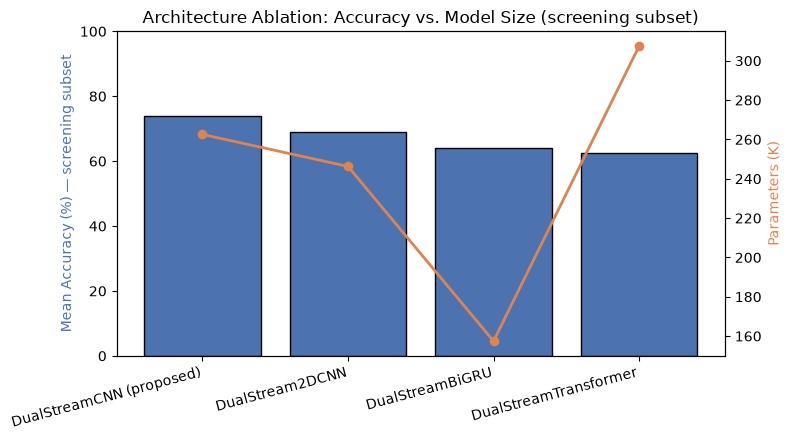

In [17]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
archs = summary_arch['architecture'].tolist()
x = np.arange(len(archs))

ax1.bar(x, summary_arch['mean_accuracy'] * 100, color='#4C72B0',
        edgecolor='black', label='Mean Accuracy (%)')
ax1.set_ylabel('Mean Accuracy (%) — screening subset', color='#4C72B0')
ax1.set_xticks(x); ax1.set_xticklabels(archs, rotation=15, ha='right')
ax1.set_ylim(0, 100)

ax2 = ax1.twinx()
ax2.plot(x, summary_arch['n_params'] / 1e3, color='#DD8452', marker='o',
         linewidth=2, label='Params (K)')
ax2.set_ylabel('Parameters (K)', color='#DD8452')

ax1.set_title('Architecture Ablation: Accuracy vs. Model Size (screening subset)')
fig.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'architecture_ablation.png'), dpi=150)
plt.show()


 9. Leave-One-Subject-Out (LOSO) Evaluation
* The official benchmark uses a fixed environment  
split; no prior work reports LOSO accuracy on ESP-Fi HAR.

 evaluate three configurations:
1. **Baseline-Amp** — single stream, amplitude only, no augmentation  
2. **Baseline-Aug** — single stream + all three augmentations  
3. **DualStream-Aug** — dual stream (amp + phase) + augmentation  ← proposed

In [18]:
CONFIGS = {
    'Baseline-Amp':    dict(model_cls=SingleStreamCNN, augment=False),
    'Baseline-Aug':    dict(model_cls=SingleStreamCNN, augment=True),
    'DualStream-Aug':  dict(model_cls=DualStreamCNN,   augment=True),
}

loso_results = {name: [] for name in CONFIGS}          
all_preds_gt = {name: ([], []) for name in CONFIGS}   

for subject_id in range(1, N_SUBJECTS + 1):
    remaining      = [s for s in range(1, N_SUBJECTS + 1) if s != subject_id]
    val_subject    = remaining[0]        
    train_subjects = remaining[1:]       

    print(f'\n=== LOSO Fold: Test subject {subject_id} '
          f'(val_subject={val_subject}, never seen by test evaluation) ===')

    y_te = y_all[subj_all == subject_id]   

    for cfg_name, cfg in CONFIGS.items():
        fold_accs = []
        run_preds = []   

        for run in range(N_RUNS):
            set_seed(SEED + subject_id * 100 + run)
            tr_dl, val_dl, te_dl = make_loaders_nested(
                X_amp, X_phase, y_all, subj_all,
                train_subjects, val_subject, subject_id,
                augment_train=cfg['augment']
            )
            model = cfg['model_cls']().to(DEVICE)
            train_model(model, tr_dl, val_dl)                     
            te_acc, te_f1, preds, gts = evaluate(model, te_dl)    
            fold_accs.append(te_acc)
            run_preds.append(preds)
            print(f'  {cfg_name}  run {run+1}/{N_RUNS}  test_acc={te_acc:.3f}')

        mean_acc = np.mean(fold_accs)
        loso_results[cfg_name].append(mean_acc)

        run_preds  = np.array(run_preds)                         
        maj_preds  = mode(run_preds, axis=0, keepdims=False).mode
        all_preds_gt[cfg_name][0].extend(maj_preds.tolist())
        all_preds_gt[cfg_name][1].extend(y_te.tolist())
        print(f'  {cfg_name}  fold mean={mean_acc:.3f}')

print('\nNested LOSO evaluation complete — no test-set leakage in model selection.')
print(f"Total majority-vote predictions collected (DualStream-Aug): "
      f"{len(all_preds_gt['DualStream-Aug'][0])}  (expected 2,240)")



=== LOSO Fold: Test subject 1 (val_subject=2, never seen by test evaluation) ===
  Baseline-Amp  run 1/3  test_acc=0.411
  Baseline-Amp  run 2/3  test_acc=0.418
  Baseline-Amp  run 3/3  test_acc=0.439
  Baseline-Amp  fold mean=0.423
  Baseline-Aug  run 1/3  test_acc=0.479
  Baseline-Aug  run 2/3  test_acc=0.461
  Baseline-Aug  run 3/3  test_acc=0.504
  Baseline-Aug  fold mean=0.481
  DualStream-Aug  run 1/3  test_acc=0.732
  DualStream-Aug  run 3/3  test_acc=0.761
  DualStream-Aug  fold mean=0.750

=== LOSO Fold: Test subject 2 (val_subject=1, never seen by test evaluation) ===
  Baseline-Amp  run 1/3  test_acc=0.429
  Baseline-Amp  run 2/3  test_acc=0.407
  Baseline-Amp  run 3/3  test_acc=0.479
  Baseline-Amp  fold mean=0.438
  DualStream-Aug  run 1/3  test_acc=0.661
  DualStream-Aug  run 3/3  test_acc=0.632
  DualStream-Aug  fold mean=0.635

=== LOSO Fold: Test subject 3 (val_subject=1, never seen by test evaluation) ===
  Baseline-Amp  run 1/3  test_acc=0.346
  Baseline-Amp  run 2/

## 10. Results Summary

In [19]:
print('=== LOSO Results (mean ± std over subjects) ===')
summary = {}
for name, accs in loso_results.items():
    m, s = np.mean(accs), np.std(accs, ddof=1)
    summary[name] = (m, s)
    print(f'{name:20s}: {m*100:.2f}% +/- {s*100:.2f}%')

dual = np.array(loso_results['DualStream-Aug'])
amp  = np.array(loso_results['Baseline-Amp'])
diff = dual - amp

t, p   = ttest_rel(dual, amp)
d      = diff.mean() / diff.std(ddof=1)                       
n      = len(diff)
se     = diff.std(ddof=1) / np.sqrt(n)
from scipy.stats import t as t_dist
tcrit  = t_dist.ppf(0.975, df=n-1)                             
ci_lo, ci_hi = diff.mean() - tcrit*se, diff.mean() + tcrit*se
w_stat, w_p  = wilcoxon(dual, amp)

print(f'\nDualStream-Aug vs Baseline-Amp (n={n} paired LOSO folds):')
print(f'  Paired t-test:        t({n-1}) = {t:.3f}, p = {p:.4f}')
print(f'  Mean diff:            {diff.mean()*100:.2f}% ± {diff.std(ddof=1)*100:.2f}% (SD)')
print(f"  Cohen's d (paired):   {d:.2f}")
print(f'  95% CI on mean diff:  [{ci_lo*100:.2f}%, {ci_hi*100:.2f}%]')
print(f'  Wilcoxon signed-rank: W = {w_stat:.3f}, p = {w_p:.4f}')
if p < 0.05:
    print('  -> DualStream-Aug significantly outperforms Baseline-Amp (p < 0.05)')
else:
    print('  -> Not significant at p = 0.05 — consider more runs or folds')


=== LOSO Results (mean ± std over subjects) ===
Baseline-Amp        : 41.74% +/- 4.34%
Baseline-Aug        : 43.54% +/- 4.98%
DualStream-Aug      : 67.54% +/- 6.77%

DualStream-Aug vs Baseline-Amp (n=8 paired LOSO folds):
  Paired t-test:        t(7) = 15.873, p = 0.0000
  Mean diff:            25.80% ± 4.60% (SD)
  Cohen's d (paired):   5.61
  95% CI on mean diff:  [21.96%, 29.65%]
  Wilcoxon signed-rank: W = 0.000, p = 0.0078
  -> DualStream-Aug significantly outperforms Baseline-Amp (p < 0.05)


## 11. Visualisations

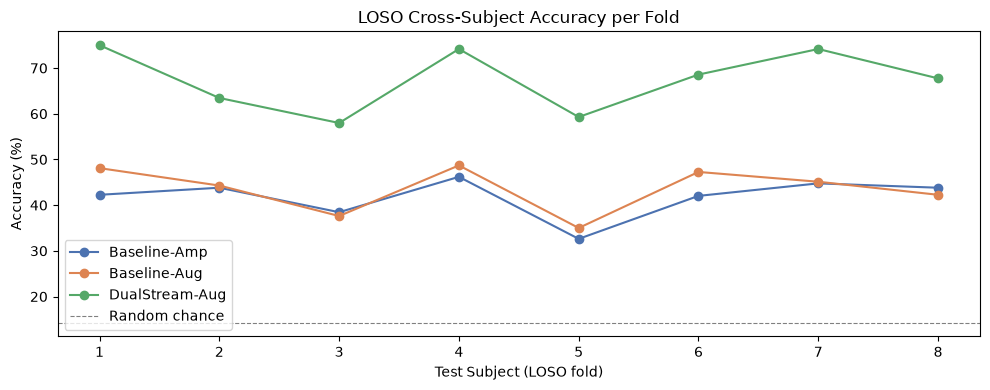

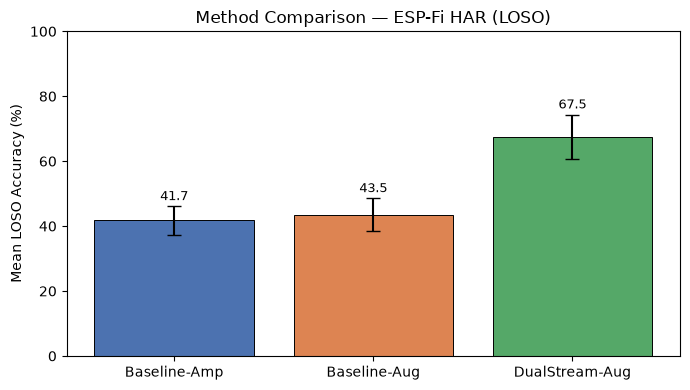

In [20]:

fig, ax = plt.subplots(figsize=(10, 4))
subjects = list(range(1, N_SUBJECTS + 1))
colors = ['#4C72B0', '#DD8452', '#55A868']
for (name, accs), col in zip(loso_results.items(), colors):
    ax.plot(subjects, [a*100 for a in accs], 'o-', label=name, color=col)
ax.axhline(100/N_CLASSES, ls='--', color='grey', lw=0.8, label='Random chance')
ax.set_xlabel('Test Subject (LOSO fold)')
ax.set_ylabel('Accuracy (%)')
ax.set_title('LOSO Cross-Subject Accuracy per Fold')
ax.set_xticks(subjects)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'loso_per_fold.png'), dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
names = list(summary.keys())
means = [summary[n][0]*100 for n in names]
stds  = [summary[n][1]*100 for n in names]
bars  = ax.bar(names, means, yerr=stds, capsize=5, color=colors[:len(names)],
               edgecolor='black', linewidth=0.7)
ax.set_ylabel('Mean LOSO Accuracy (%)')
ax.set_title('Method Comparison — ESP-Fi HAR (LOSO)')
ax.set_ylim(0, 100)
for bar, m, s in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + s + 1,
            f'{m:.1f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'method_comparison.png'), dpi=150)
plt.show()

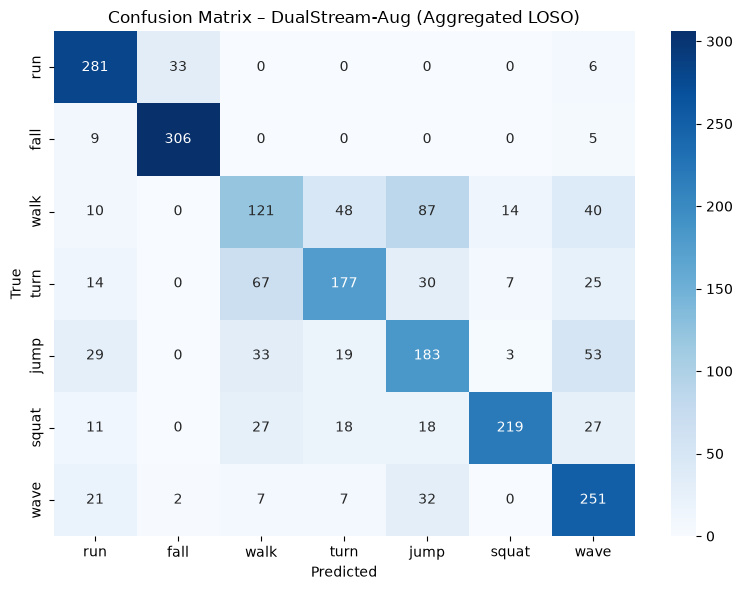


Classification Report – DualStream-Aug:
              precision    recall  f1-score   support

         run       0.75      0.88      0.81       320
        fall       0.90      0.96      0.93       320
        walk       0.47      0.38      0.42       320
        turn       0.66      0.55      0.60       320
        jump       0.52      0.57      0.55       320
       squat       0.90      0.68      0.78       320
        wave       0.62      0.78      0.69       320

    accuracy                           0.69      2240
   macro avg       0.69      0.69      0.68      2240
weighted avg       0.69      0.69      0.68      2240



In [21]:

preds_all = np.array(all_preds_gt['DualStream-Aug'][0])
gts_all   = np.array(all_preds_gt['DualStream-Aug'][1])
cm = confusion_matrix(gts_all, preds_all)

activity_names = [ACTIVITY_MAP[i+1] for i in range(N_CLASSES)]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=activity_names, yticklabels=activity_names, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Confusion Matrix – DualStream-Aug (Aggregated LOSO)')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix_dual.png'), dpi=150)
plt.show()

print('\nClassification Report – DualStream-Aug:')
print(classification_report(gts_all, preds_all, target_names=activity_names))

## 12. Save Results to CSV (for the paper table)

In [22]:
rows = []
for name, accs in loso_results.items():
    for fold_i, acc in enumerate(accs, 1):
        rows.append({'method': name, 'fold_subject': fold_i, 'accuracy': acc})

df_results = pd.DataFrame(rows)
df_results.to_csv(os.path.join(OUTPUT_DIR, 'loso_results.csv'), index=False)

# Summary table
summary_df = pd.DataFrame([
    {'Method': n,
     'Mean Acc (%)': f'{summary[n][0]*100:.2f}',
     'Std (%)':      f'{summary[n][1]*100:.2f}',
     'Mean F1':      f'{f1_score(np.array(all_preds_gt[n][1]), np.array(all_preds_gt[n][0]), average="macro"):.4f}'}
    for n in CONFIGS
])
print(summary_df.to_string(index=False))
summary_df.to_csv(os.path.join(OUTPUT_DIR, 'summary_table.csv'), index=False)
print('\nResults saved to ./results/')

        Method Mean Acc (%) Std (%) Mean F1
  Baseline-Amp        41.74    4.34  0.4367
  Baseline-Aug        43.54    4.98  0.4444
DualStream-Aug        67.54    6.77  0.6816

Results saved to ./results/
